In [1]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, run_psy
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


### Import target series and detrend series with HP filter lambda=129600

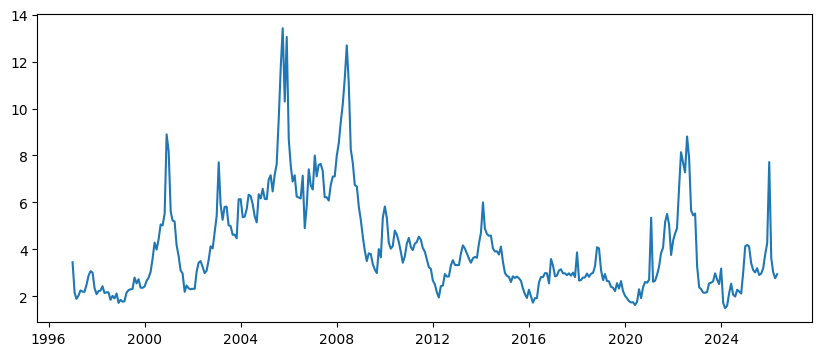

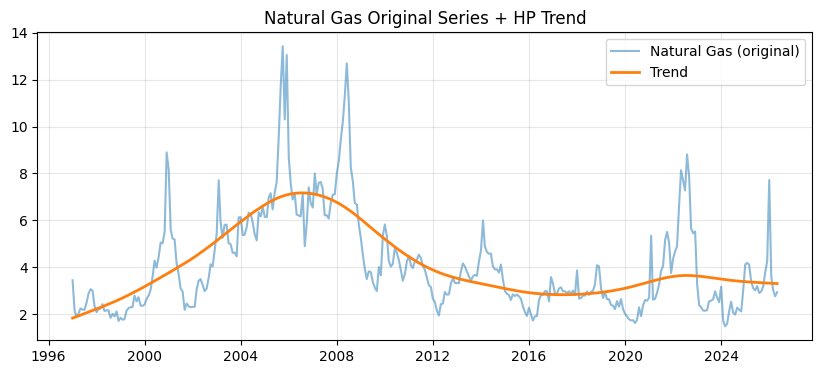

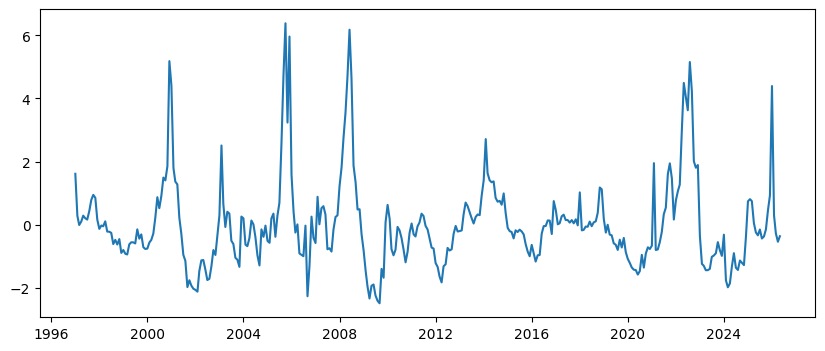

In [2]:
# -------------------------
# DATA
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter
cycle, trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

df_ngas["gas_cycle"] = cycle
df_ngas["gas_trend"] = trend

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"])
#plt.ylabel("Dollars per Million BTU \n",fontsize=18)
# Increase tick-label font size (axis scales)
#plt.tick_params(axis="both", labelsize=14)
plt.show()


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"], label="Natural Gas (original)", alpha=0.5)
plt.plot(df_ngas.index, df_ngas["gas_trend"], label="Trend", linewidth=2)
plt.title("Natural Gas Original Series + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_cycle"])
#plt.ylabel("HP-detrended Price \n", fontsize=18)
# Increase tick-label font size (axis scales)
#plt.tick_params(axis="both", labelsize=14)
plt.show()



### Create PSY results and save as PICKLE only need to run 1 time for each commodity

In [3]:


T = len(df_ngas)
r0 = 0.01 + 1.8 / np.sqrt(T)
swindow0 = int(np.floor(r0 * T))
yr = 2
Tb = 12 * yr + swindow0 - 1

psy = run_psy(
    y=df_ngas["MHHNGSP"].values,
    dates=df_ngas.index,
    IC=2,
    adflag=6,
    Tb = Tb,
    nboot=1999)


with open("psy_ngas.pkl", "wb") as f:
    pickle.dump(psy, f)

### Extract Data for Exogeous Variables

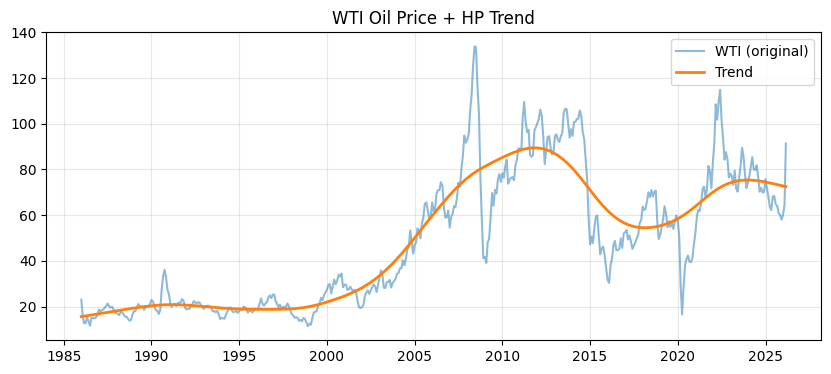

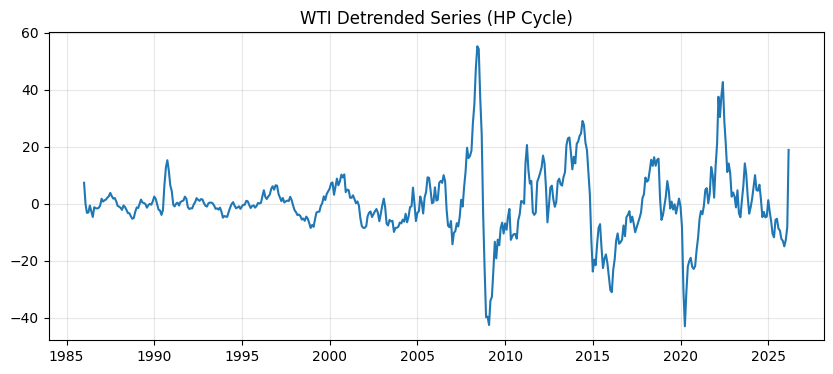

In [4]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter
wti, wti_trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_wti.index, df_wti["MCOILWTICO"], label="WTI (original)", alpha=0.5)
plt.plot(df_wti.index, wti_trend, label="Trend", linewidth=2)
plt.title("WTI Oil Price + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(wti.index, wti)
plt.title("WTI Detrended Series (HP Cycle)")
plt.grid(True, alpha=0.3)
plt.show()


/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_77182/1630632948.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


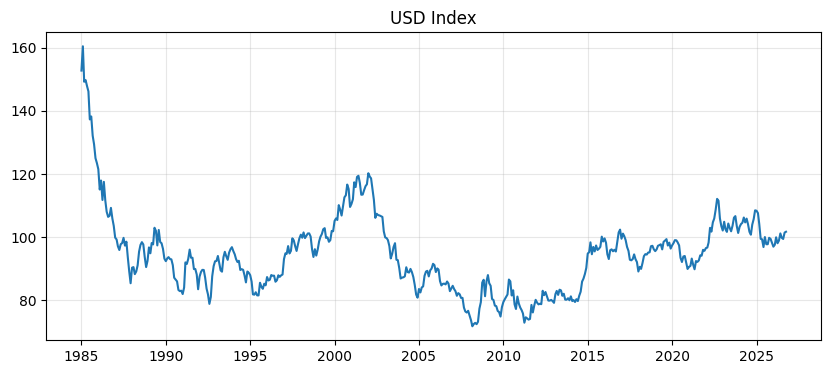

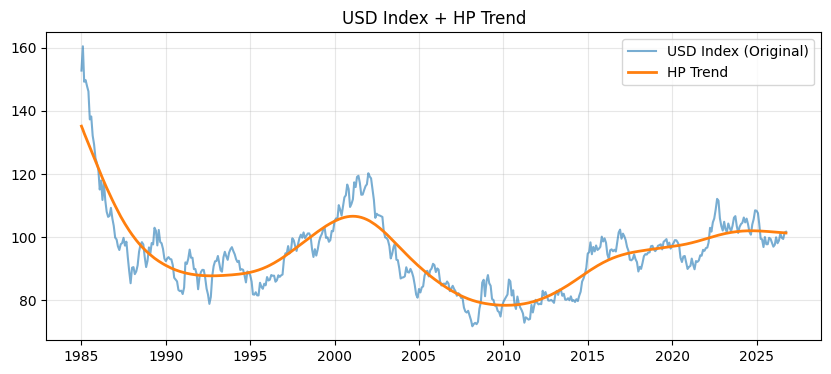

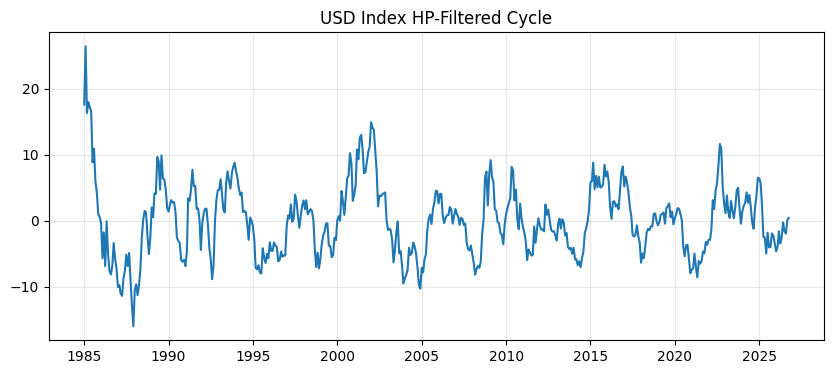

In [5]:
# -------------------------
# USD INDEX
# -------------------------
usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
usd_ind_original = usd_ind_original.dropna()

plt.figure(figsize=(10,4))
plt.plot(usd_ind_original)
plt.title("USD Index")
plt.grid(alpha=0.3)
plt.show()

# -------------------------
# HP Filter 
# -------------------------
usd_ind, trend = hpfilter(usd_ind_original, lamb=129600)

# -------------------------
# PLOT ORIGINAL + TREND
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(usd_ind_original, label="USD Index (Original)", alpha=0.6)
plt.plot(trend, label="HP Trend", linewidth=2)
plt.title("USD Index + HP Trend")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(usd_ind)
plt.title("USD Index HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()


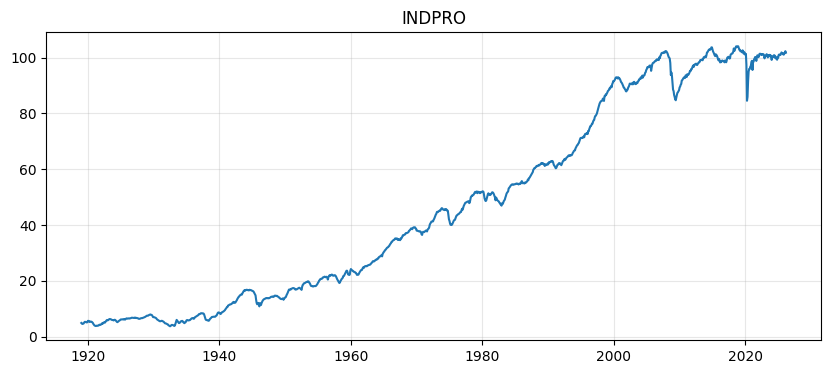

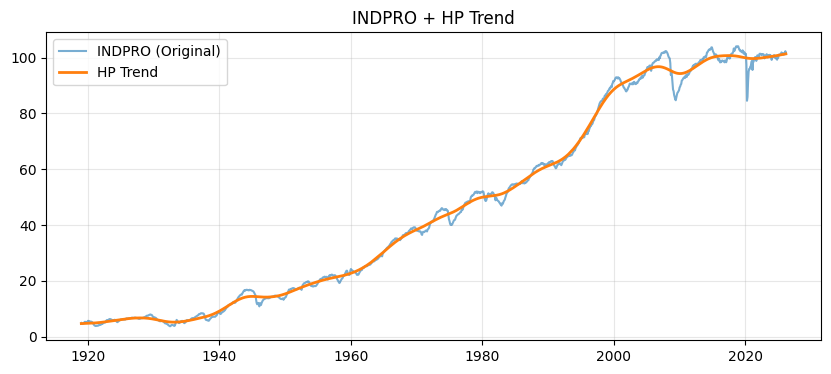

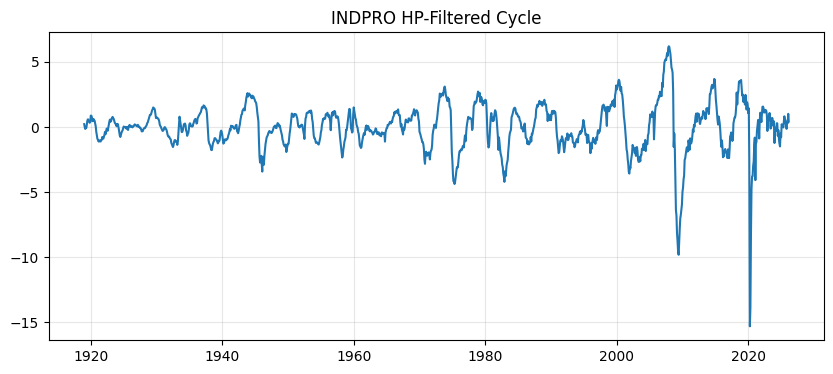

In [6]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")

plt.figure(figsize=(10,4))
plt.plot(indpro_original)
plt.title("INDPRO")
plt.grid(alpha=0.3)
plt.show()

# -------------------------
# HP Filter 
# -------------------------
indpro, trend = hpfilter(indpro_original, lamb=129600)

# -------------------------
# PLOT ORIGINAL + TREND
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(indpro_original, label="INDPRO (Original)", alpha=0.6)
plt.plot(trend, label="HP Trend", linewidth=2)
plt.title("INDPRO + HP Trend")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("INDPRO HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

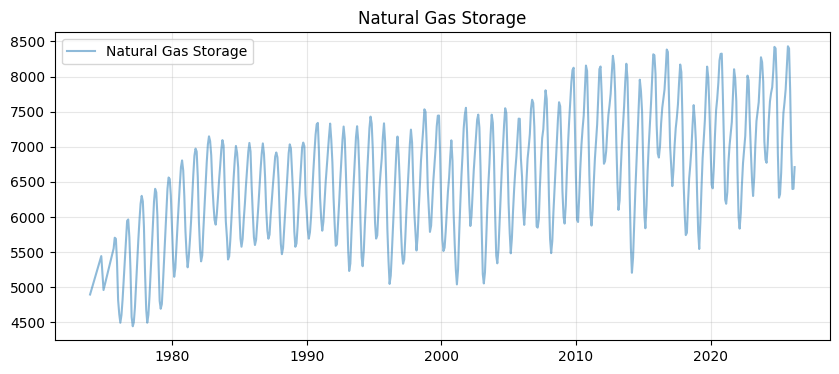

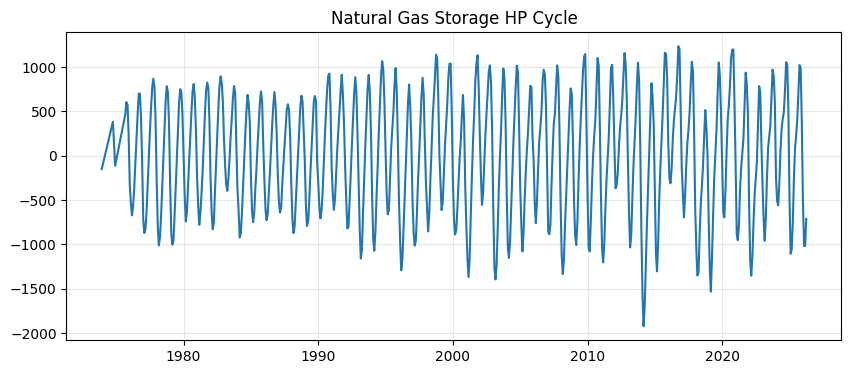

In [7]:
# -------------------------
# Natural Gas Storage
# -------------------------

df_ngas_storage = pd.read_excel(
    "Natural Gas Storage.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column (e.g., Jan-1997)
df_ngas_storage["Date"] = pd.to_datetime(
    df_ngas_storage["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_storage["Date"] = df_ngas_storage["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_storage = df_ngas_storage.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------

df_ngas_storage=0.001*df_ngas_storage
ngas_storage, trend = hpfilter(
    df_ngas_storage["U.S. Natural Gas Underground Storage Volume (MMcf)"],
    lamb=129600
)

# -------------------------
# Plot Original Series + Trend
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(
    df_ngas_storage.index,
    df_ngas_storage["U.S. Natural Gas Underground Storage Volume (MMcf)"],
    alpha=0.5,
    label="Natural Gas Storage"
)
plt.title("Natural Gas Storage")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# -------------------------
# Plot HP Cycle
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(df_ngas_storage.index, ngas_storage)
plt.title("Natural Gas Storage HP Cycle")
plt.grid(alpha=0.3)
plt.show()

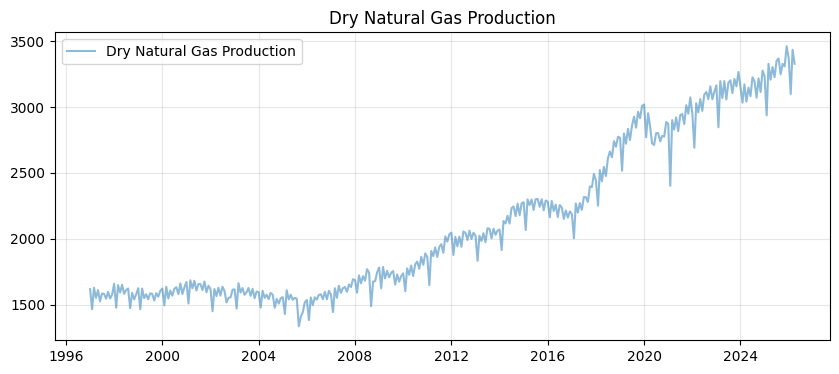

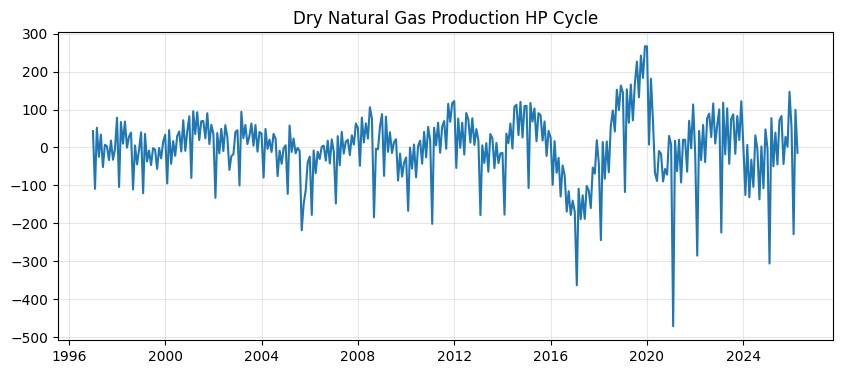

In [8]:
# -------------------------
# Dry Natural Gas Production
# -------------------------

df_ngas_prod = pd.read_excel(
    "Dry NGas Production.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column (e.g., Jan-1997)
df_ngas_prod["Date"] = pd.to_datetime(
    df_ngas_prod["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_prod["Date"] = df_ngas_prod["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_prod = df_ngas_prod.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_ngas_prod=0.001*df_ngas_prod
ngas_prod, trend = hpfilter(
    df_ngas_prod["U.S. Dry Natural Gas Production (MMcf)"],
    lamb=129600
)

# -------------------------
# Plot Original Series + Trend
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(
    df_ngas_prod.index,
    df_ngas_prod["U.S. Dry Natural Gas Production (MMcf)"],
    alpha=0.5,
    label="Dry Natural Gas Production"
)

plt.title("Dry Natural Gas Production")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# -------------------------
# Plot HP Cycle
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(df_ngas_prod.index, ngas_prod)
plt.title("Dry Natural Gas Production HP Cycle")
plt.grid(alpha=0.3)
plt.show()

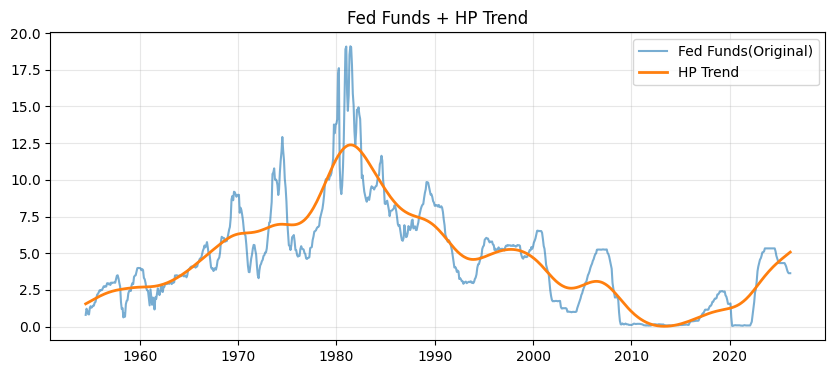

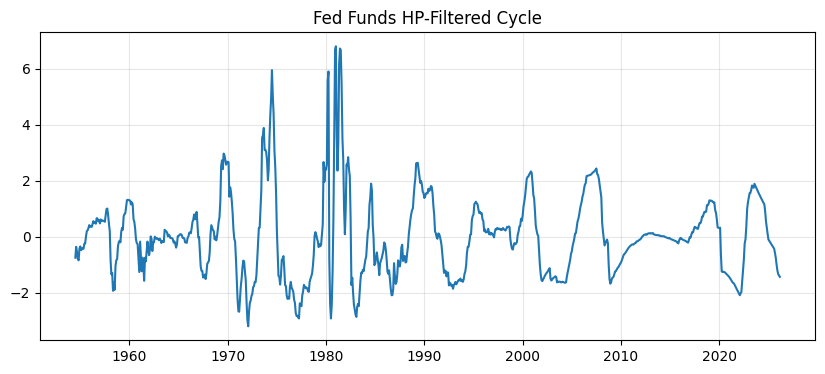

In [9]:
# -------------------------
# Fed Funds
# -------------------------
fedfunds_original = pd.read_csv("FEDFUNDS.csv", parse_dates=["observation_date"])
fedfunds_original = fedfunds_original.dropna().set_index("observation_date")

# -------------------------
# HP Filter 
# -------------------------
fedfunds, trend = hpfilter(fedfunds_original, lamb=129600)

# -------------------------
# PLOT ORIGINAL + TREND
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(fedfunds_original, label="Fed Funds(Original)", alpha=0.6)
plt.plot(trend, label="HP Trend", linewidth=2)
plt.title("Fed Funds + HP Trend")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(fedfunds)
plt.title("Fed Funds HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_77182/1535686848.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


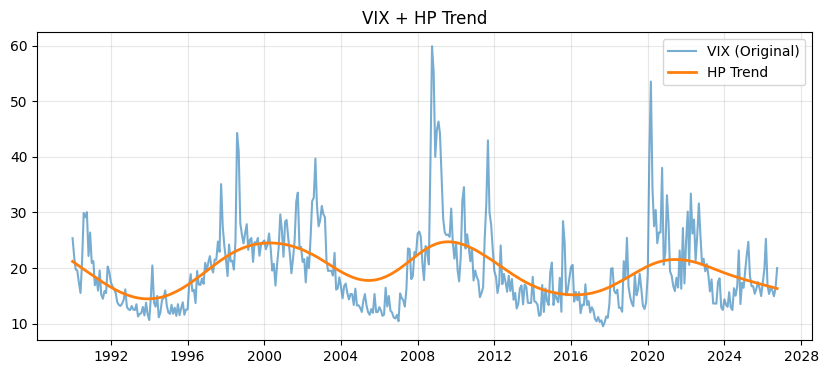

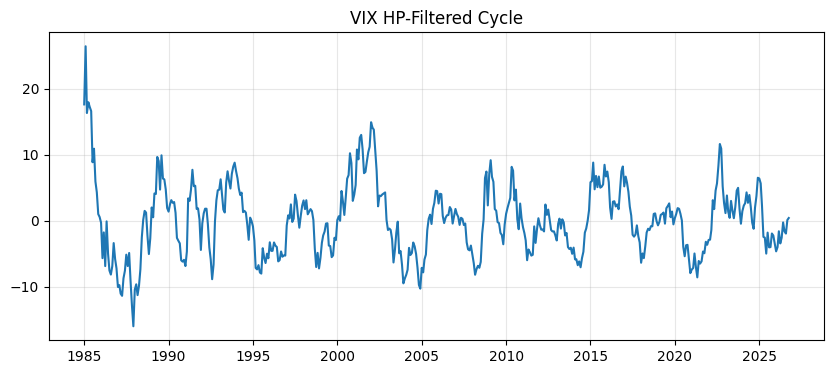

In [10]:
# -------------------------
# VIX
# -------------------------
vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
vix_original = vix_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
vix, trend = hpfilter(vix_original, lamb=129600)

# -------------------------
# PLOT ORIGINAL + TREND
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(vix_original, label="VIX (Original)", alpha=0.6)
plt.plot(trend, label="HP Trend", linewidth=2)
plt.title("VIX + HP Trend")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(usd_ind)
plt.title("VIX HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

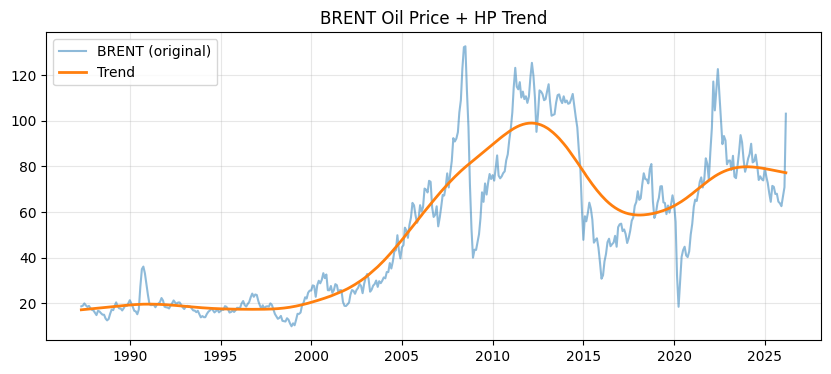

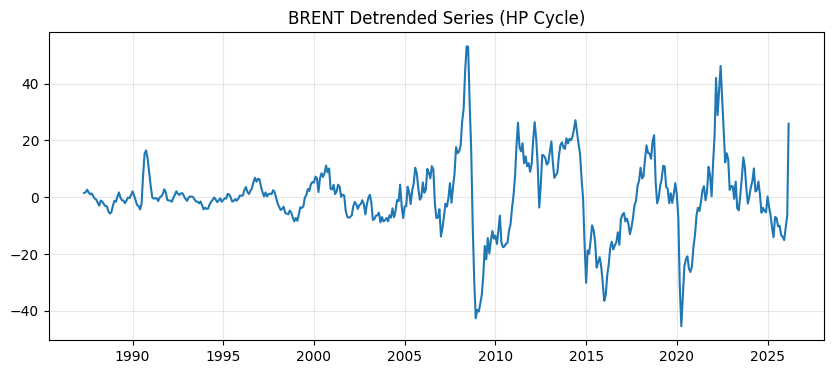

In [11]:
# -------------------------
# BRENT DATA
# -------------------------
df_brent = pd.read_csv("MCOILBRENTEU.csv", parse_dates=["observation_date"])
df_brent = df_brent.dropna().set_index("observation_date")

# HP filter
brent, brent_trend = hpfilter(df_brent["MCOILBRENTEU"], lamb=129600)


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_brent.index, df_brent["MCOILBRENTEU"], label="BRENT (original)", alpha=0.5)
plt.plot(df_brent.index, brent_trend, label="Trend", linewidth=2)
plt.title("BRENT Oil Price + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(brent.index, brent)
plt.title("BRENT Detrended Series (HP Cycle)")
plt.grid(True, alpha=0.3)
plt.show()

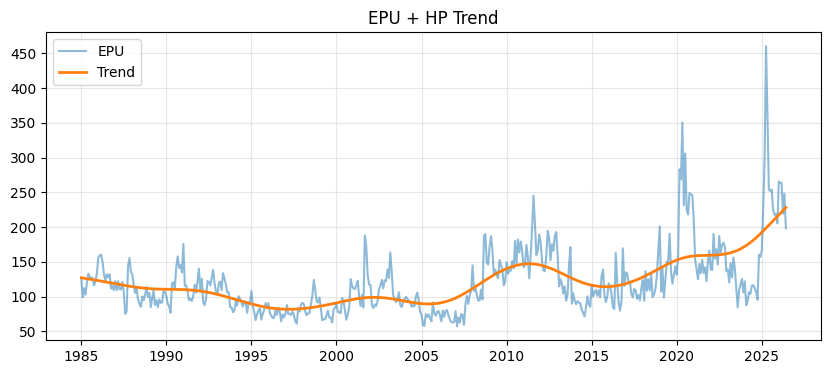

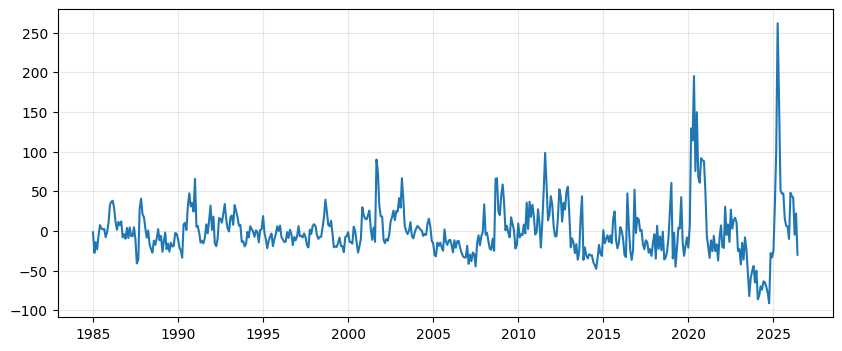

In [12]:
# -------------------------
# Economic Policy Uncertainty US
# -------------------------
df_epu = pd.read_csv("USEPUINDXM.csv", parse_dates=["observation_date"])
df_epu = df_epu.dropna().set_index("observation_date")


# HP filter
epu , trend = hpfilter(df_epu["USEPUINDXM"], lamb=129600)



# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_epu.index, df_epu["USEPUINDXM"], label="EPU", alpha=0.5)
plt.plot(df_epu.index, trend, label="Trend", linewidth=2)
plt.title("EPU + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_epu.index, epu)
plt.grid(True, alpha=0.3)
plt.show()

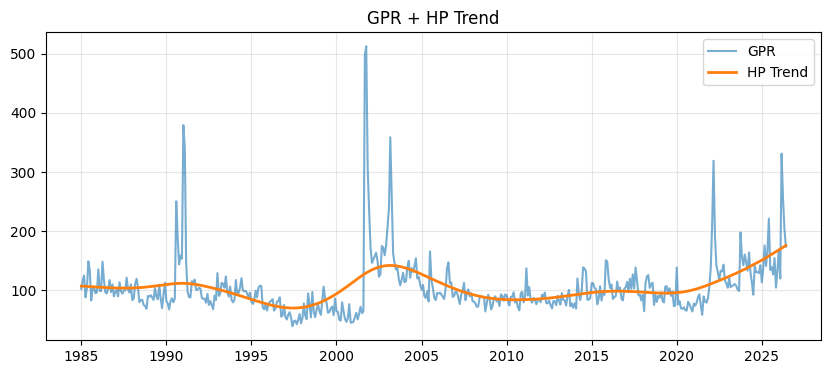

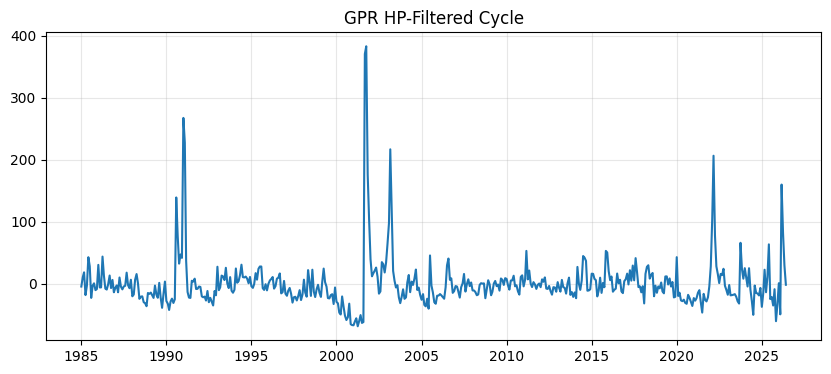

In [13]:
# -------------------------
# GPR
# -------------------------
df = pd.read_excel("GPR.xls", usecols=["month", "GPR"])

# Convert Month column to datetime
df["month"] = pd.to_datetime(df["month"])

# Set Month as index
df = df.set_index("month")

# Extract GPR series
gpr_original = df["GPR"].dropna()

# -------------------------
# HP Filter
# -------------------------
gpr, gpr_trend = hpfilter(gpr_original, lamb=129600)

# -------------------------
# Plot Original + Trend
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(gpr_original, label="GPR", alpha=0.6)
plt.plot(gpr_trend, label="HP Trend", linewidth=2)
plt.title("GPR + HP Trend")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# -------------------------
# Plot Cyclical Component
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(gpr)
plt.title("GPR HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

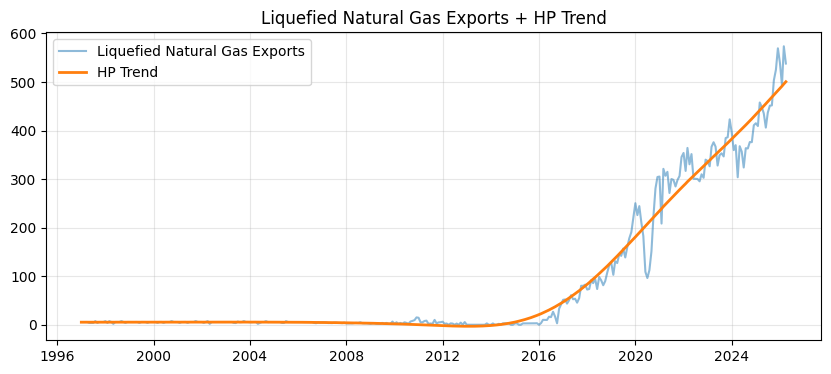

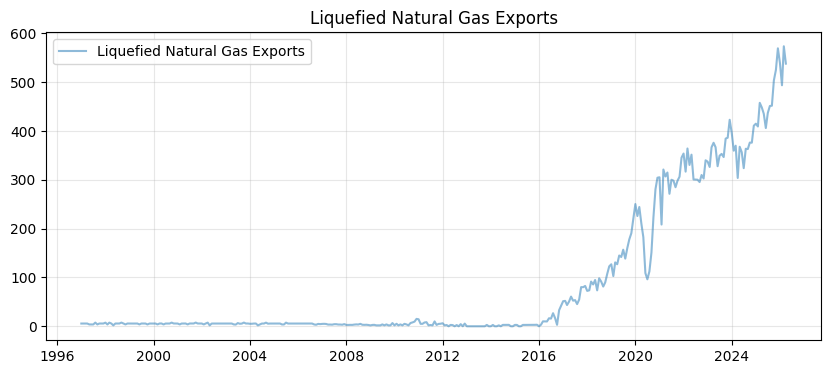

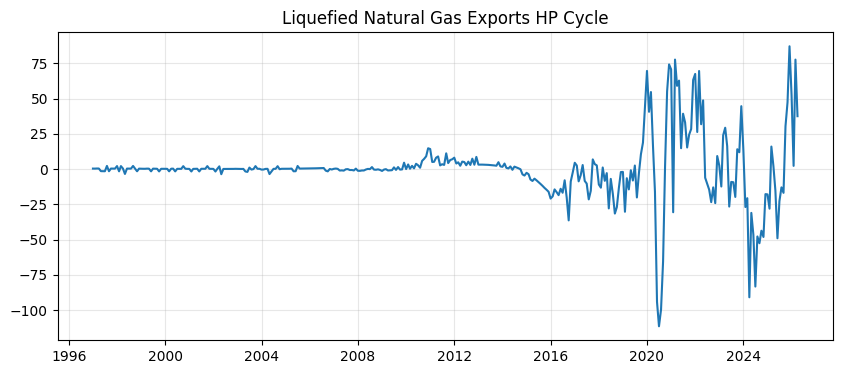

In [14]:
# -------------------------
# LNGas Exports
# -------------------------

df_ngas_exports = pd.read_excel(
    "LNG Exports.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column
df_ngas_exports["Date"] = pd.to_datetime(
    df_ngas_exports["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_exports["Date"] = df_ngas_exports["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_exports = df_ngas_exports.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_ngas_exports=0.001*df_ngas_exports
ngas_exports, trend = hpfilter(
    df_ngas_exports["Liquefied U.S. Natural Gas Exports (MMcf)"],
    lamb=129600
)

# -------------------------
# Plot Original Series + Trend
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(
    df_ngas_exports.index,
    df_ngas_exports["Liquefied U.S. Natural Gas Exports (MMcf)"],
    alpha=0.5,
    label="Liquefied Natural Gas Exports"
)
plt.plot(
    df_ngas_exports.index,
    trend,
    linewidth=2,
    label="HP Trend"
)
plt.title("Liquefied Natural Gas Exports + HP Trend")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(
    df_ngas_exports.index,
    df_ngas_exports["Liquefied U.S. Natural Gas Exports (MMcf)"],
    alpha=0.5,
    label="Liquefied Natural Gas Exports"
)
plt.title("Liquefied Natural Gas Exports")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# -------------------------
# Plot HP Cycle
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(df_ngas_exports.index, ngas_exports)
plt.title("Liquefied Natural Gas Exports HP Cycle")
plt.grid(alpha=0.3)
plt.show()

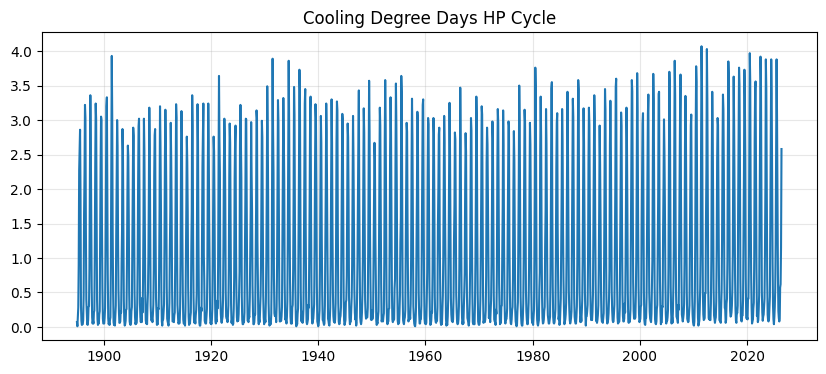

In [15]:
# -------------------------
# Cooling Degree Days
# -------------------------
df_cdd = pd.read_csv(
    "CDD.csv",
    skiprows=2,
    parse_dates=["Date"],
    date_format="%Y%m"
)

df_cdd = df_cdd.set_index("Date").dropna()

cdd=0.01*df_cdd



plt.figure(figsize=(10,4))
plt.plot(df_cdd.index, cdd)
plt.title("Cooling Degree Days HP Cycle")
plt.grid(alpha=0.3)
plt.show()

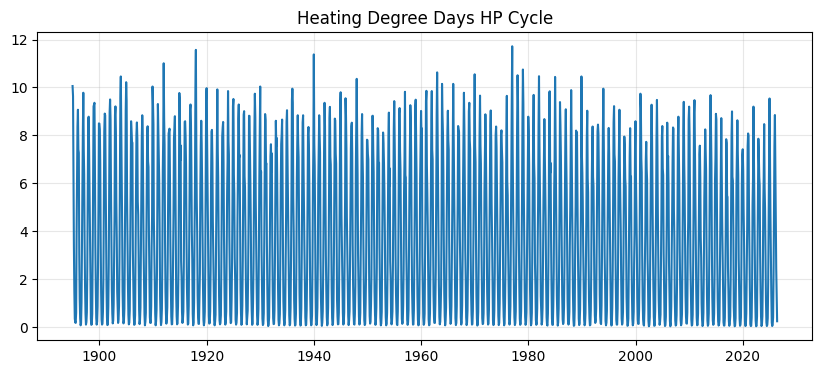

In [16]:
# -------------------------
# Heating Degree Days
# -------------------------
df_hdd = pd.read_csv(
    "HDD.csv",
    skiprows=2,
    parse_dates=["Date"],
    date_format="%Y%m"
)

df_hdd = df_hdd.set_index("Date").dropna()

hdd=0.01*df_hdd


plt.figure(figsize=(10,4))
plt.plot(df_hdd.index, hdd)
plt.title("Heating Degree Days HP Cycle")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_77182/1983831287.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


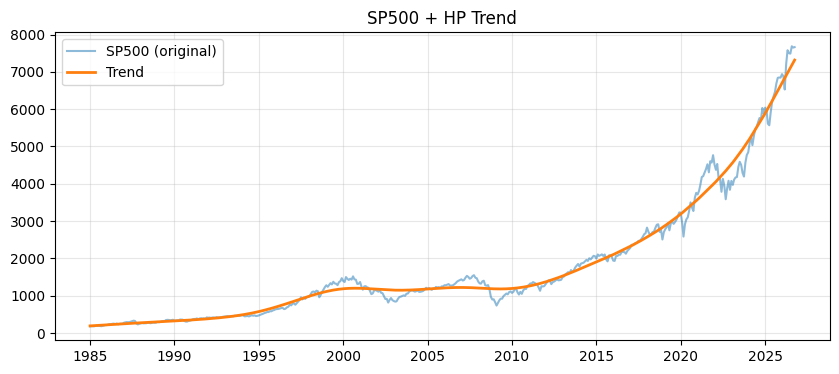

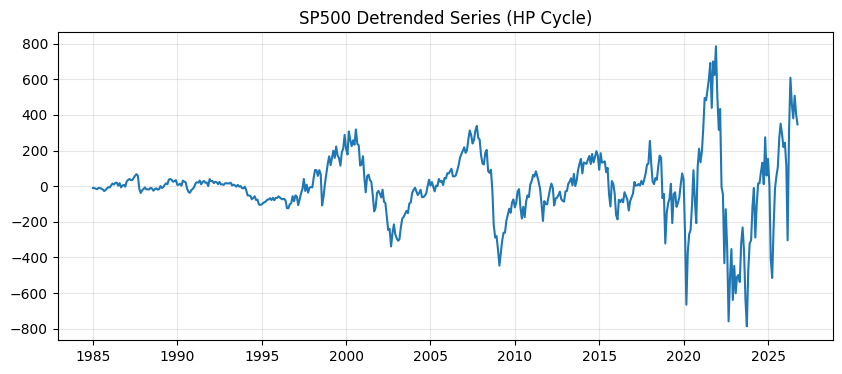

In [17]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter
sp500, trend = hpfilter(sp500_original, lamb=129600)


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot( sp500_original, label="SP500 (original)", alpha=0.5)
plt.plot(trend, label="Trend", linewidth=2)
plt.title("SP500 + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 Detrended Series (HP Cycle)")
plt.grid(True, alpha=0.3)
plt.show()

### Prepare Data and Parameters

In [18]:
# Data and Parameters 
df = pd.concat(
    [
        df_ngas["gas_cycle"], wti, usd_ind, indpro, ngas_storage, ngas_prod, fedfunds, vix, brent, epu, gpr, ngas_exports, hdd, cdd, sp500
    ],
    axis=1
).dropna()

df.columns = ["gas_cycle",  "wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr", "ngas_exports", "hdd", "cdd", "sp500"]
df = df.sort_index()

# Define sample start and end date
start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()


y = df["gas_cycle"].values
X = df[["wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr", "ngas_exports", "hdd", "cdd", "sp500"]].values

var = ["wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr", "ngas_exports", "hdd", "cdd", "sp500"]

t0=len(y)-3 # point to calculate predictive density

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")


#Define Grid for all experiments
grid_min=-50
grid_max=50
ngrid=3000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=3
values=30

prominence = 0.01

y_limits=(-5, 10)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -307.50397841971585

Estimated parameters:
phi             =     0.2456 (0.0255)
psi             =     0.7990 (0.0212)
sigma           =     0.2446 (0.0175)

Hessian condition number:
2.3861448049889975

Eigenvalues of Hessian:
[1413.67147939 2489.91748219 3373.2248565 ]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -307.503978
AIC:            621.007957
BIC:            632.564564
R^2:            0.685517

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 15.200385, p-value = 9.66837e-05
    lag  5: statistic = 28.320954, p-value = 3.15e-05
    lag 10: statistic = 40.439883, p-value = 1.41737e-05
    lag 20: statistic = 46.523053, p-value = 0.000682897

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 24.690582, p-value = 6.73123e-07
    lag  5

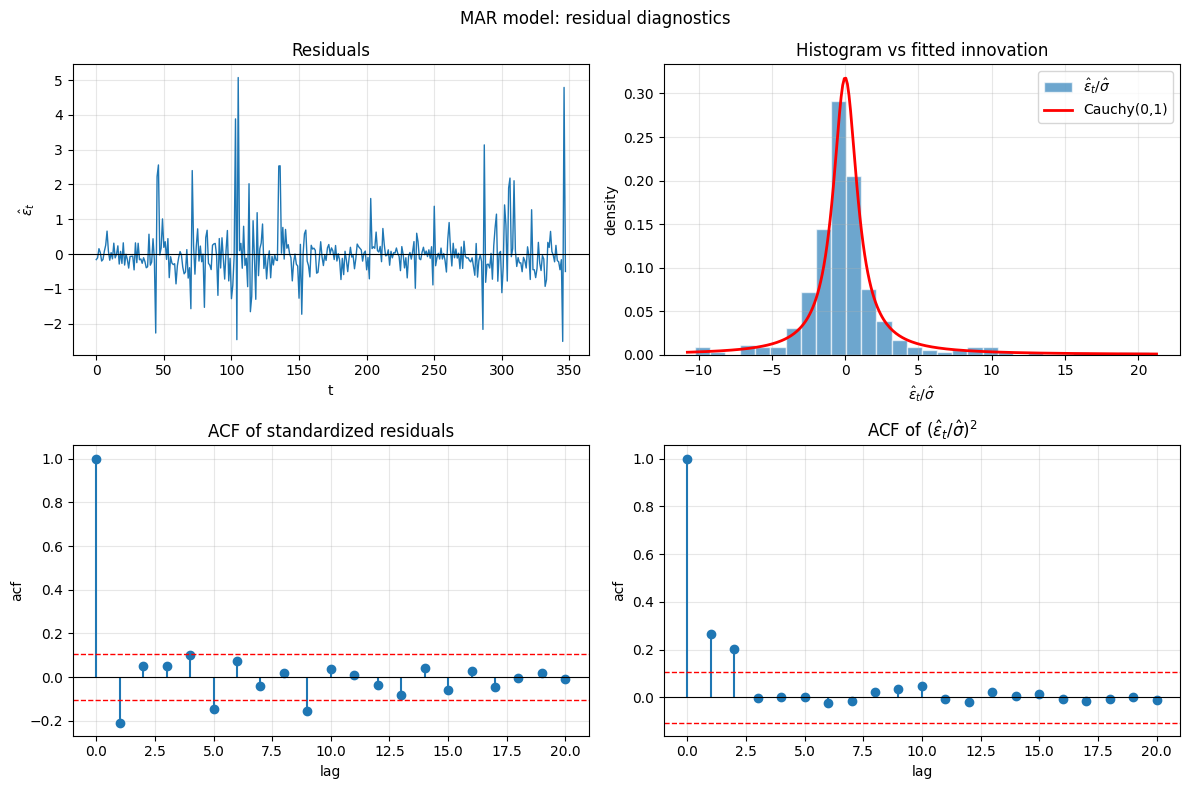

In [19]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

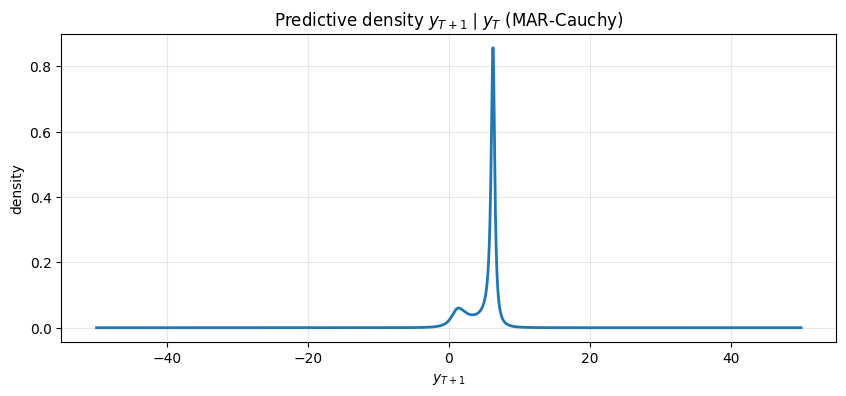

In [20]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

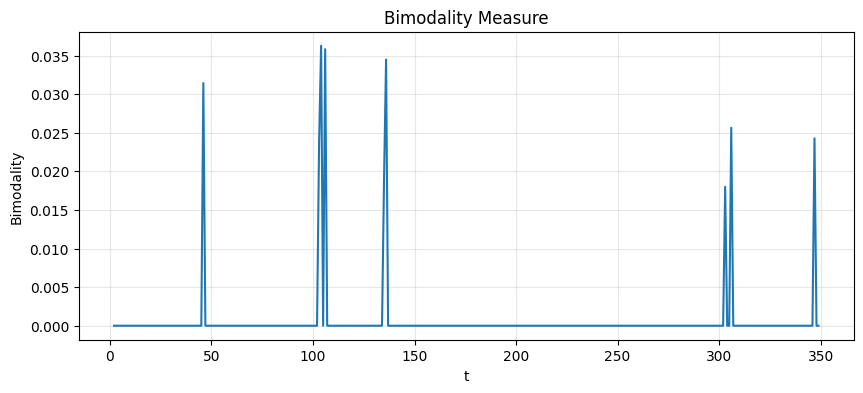

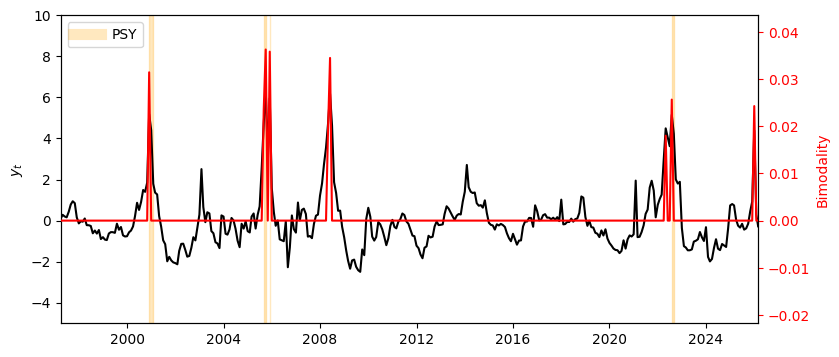

In [21]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -296.03372358164614

Estimated parameters:
phi             =     0.2493 (0.0440)
psi             =     0.7463 (0.0437)
beta_wti        =     0.0057 (0.0069)
beta_usd_ind    =     0.0052 (0.0068)
beta_indpro     =     0.0278 (0.0115)
beta_ngas_storage =    -0.0000 (0.0000)
beta_ngas_prod  =    -0.0003 (0.0003)
beta_fedfunds   =    -0.0465 (0.0341)
beta_vix        =     0.0006 (0.0044)
beta_brent      =    -0.0034 (0.0057)
beta_epu        =     0.0004 (0.0006)
beta_gpr        =    -0.0006 (0.0006)
beta_ngas_exports =     0.0004 (0.0016)
beta_hdd        =    -0.0162 (0.0059)
beta_cdd        =    -0.0157 (0.0125)
beta_sp500      =    -0.0002 (0.0002)
sigma           =     0.2374 (0.0177)

Hessian condition number:
4020288.0544006894

Eigenvalues of Hessian:
[1.35573369e+09 8.50149328e+07 2.25395588e+07 4.78635407e+06
 3.45414613e+06 9.56696144e+05 5.61808292e+05 5.41082351e+04
 4.36019950e+04 2.72175416e+04 1.66684136e+04 1.07902309e+04
 6.7536809

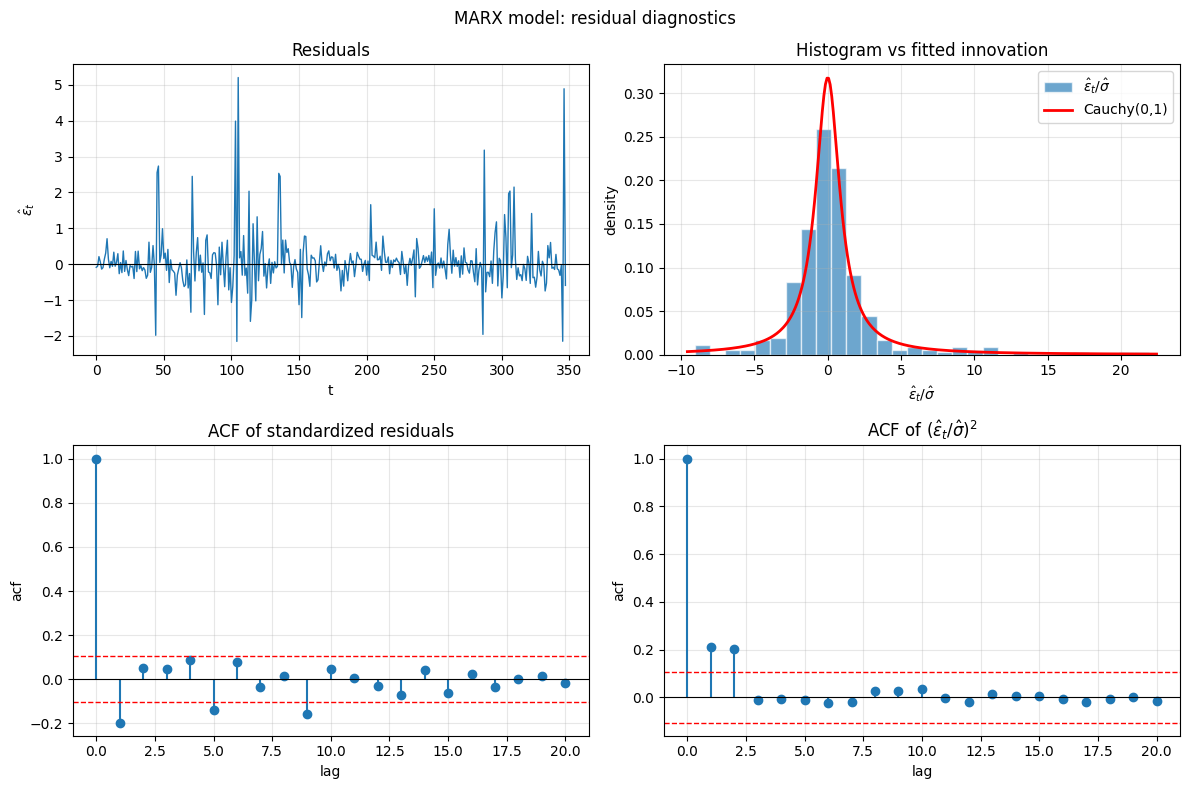

In [22]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_wti", "beta_usd_ind", "beta_indpro", "beta_ngas_storage", "beta_ngas_prod", "beta_fedfunds", "beta_vix", "beta_brent", "beta_epu", "beta_gpr", "beta_ngas_exports", "beta_hdd", "beta_cdd", "beta_sp500", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

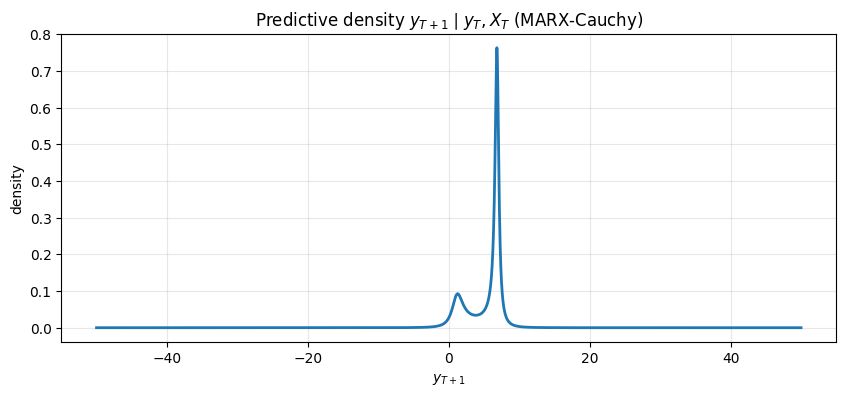

In [23]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

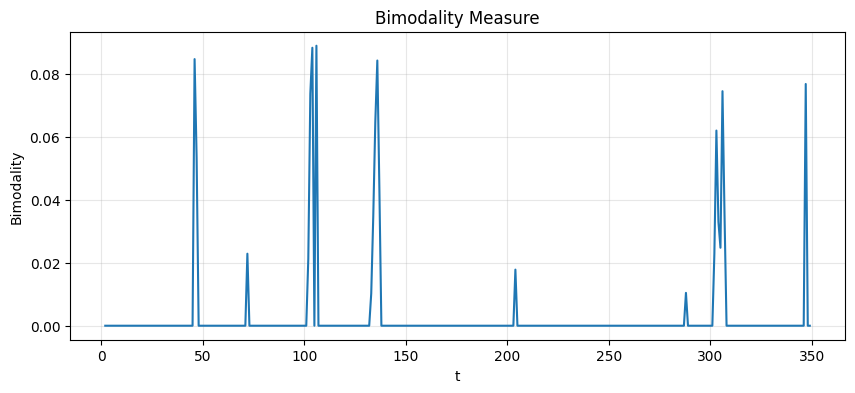

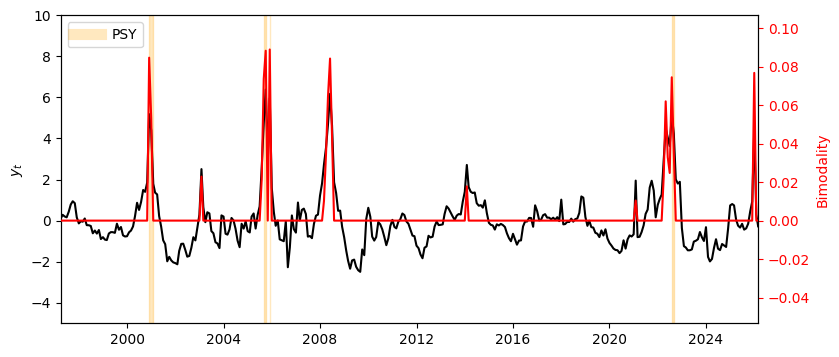

In [24]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -297.64750538020814

Estimated parameters:
phi             =     0.2268 (0.0342)
psi             =     0.7891 (0.0238)
sigma           =     0.3192 (0.0262)
nu              =     2.0100 (0.2989)

Hessian condition number:
244.84212699547123

Eigenvalues of Hessian:
[2729.77444213 2077.16098177  801.92338096   11.14912076]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -297.647505
AIC:            603.295011
BIC:            618.703821
R^2:            0.688482

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 11.504770, p-value = 0.000694178
    lag  5: statistic = 24.744555, p-value = 0.000156081
    lag 10: statistic = 36.542970, p-value = 6.7875e-05
    lag 20: statistic = 42.704844, p-value = 0.00223601

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: st

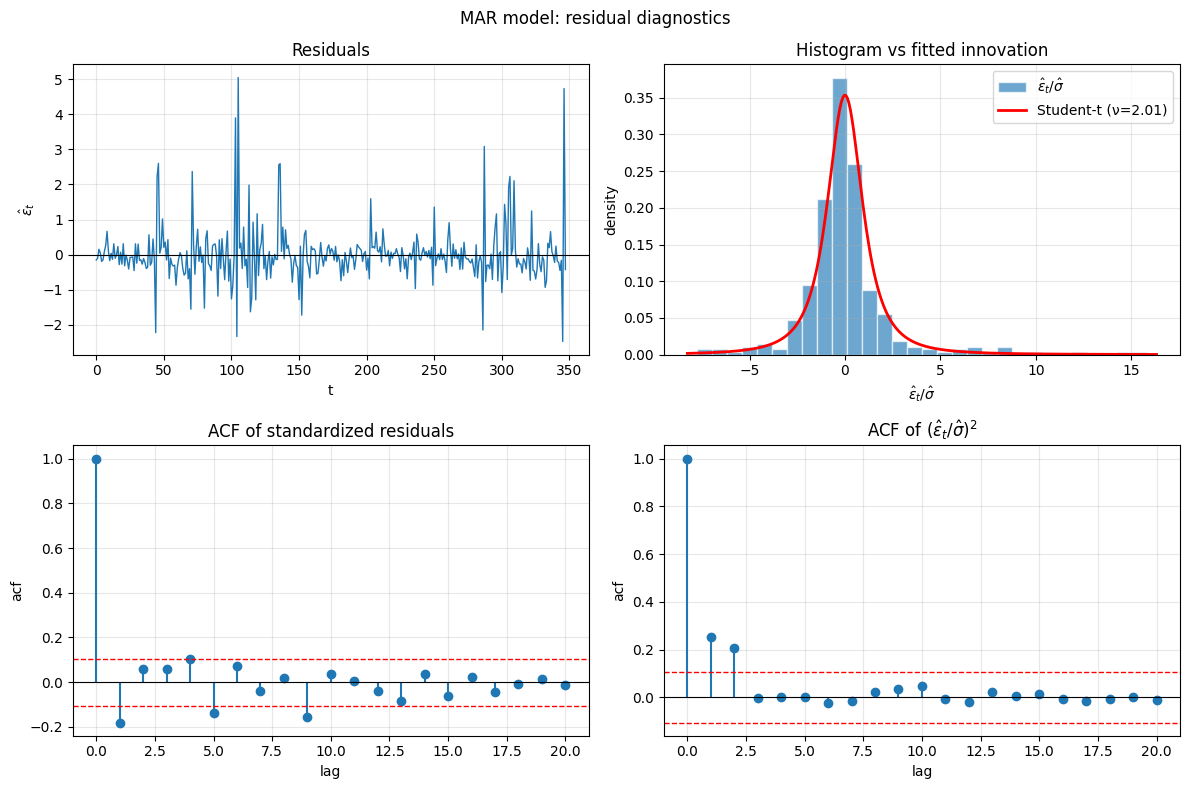

In [25]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

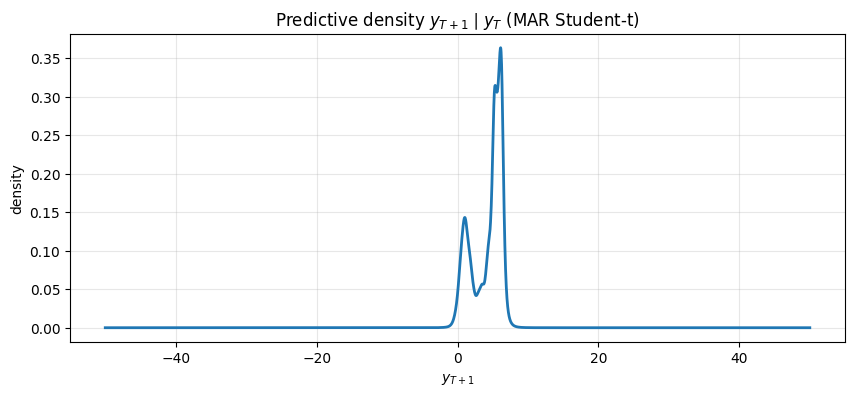

In [26]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

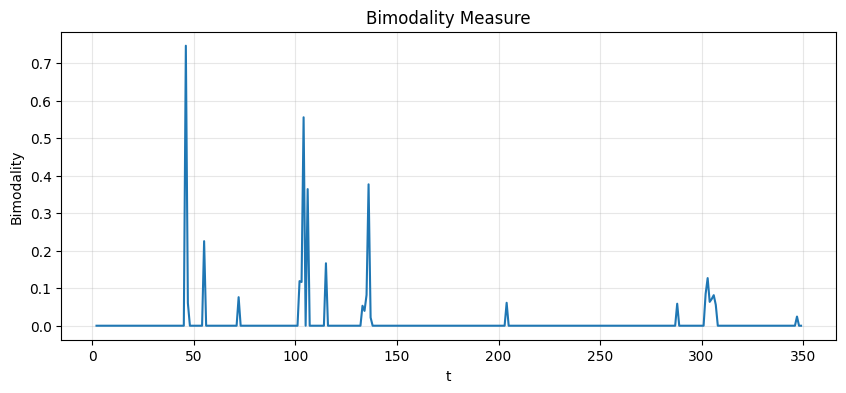

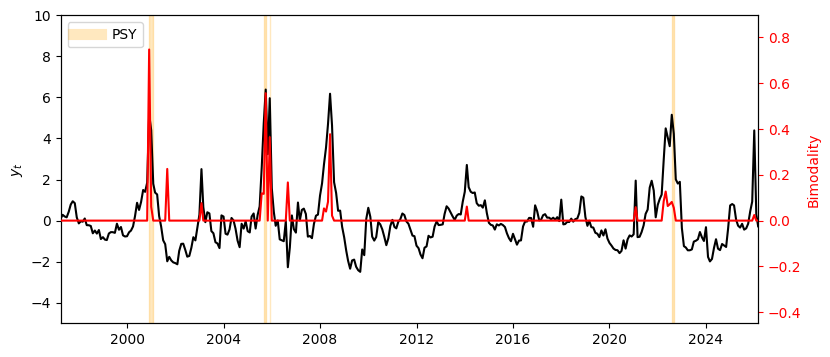

In [27]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -283.08631503926324

Estimated parameters:
phi             =     0.2556 (0.0427)
psi             =     0.6663 (0.0469)
beta_wti        =     0.0153 (0.0077)
beta_usd_ind    =     0.0066 (0.0060)
beta_indpro     =     0.0374 (0.0148)
beta_ngas_storage =    -0.0000 (0.0000)
beta_ngas_prod  =    -0.0003 (0.0003)
beta_fedfunds   =    -0.0701 (0.0383)
beta_vix        =     0.0027 (0.0048)
beta_brent      =    -0.0089 (0.0066)
beta_epu        =     0.0008 (0.0007)
beta_gpr        =    -0.0016 (0.0007)
beta_ngas_exports =    -0.0002 (0.0014)
beta_hdd        =    -0.0168 (0.0062)
beta_cdd        =    -0.0278 (0.0136)
beta_sp500      =    -0.0001 (0.0002)
sigma           =     0.3148 (0.0244)
nu              =     2.0100 (0.2837)

Hessian condition number:
89207606.58145168

Eigenvalues of Hessian:
[1.10302267e+09 7.15884863e+07 1.60333427e+07 3.09681086e+06
 2.74431374e+06 6.53536277e+05 5.74083263e+05 4.73211630e+04
 3.53462925e+04 3.01003220e+04 1.1

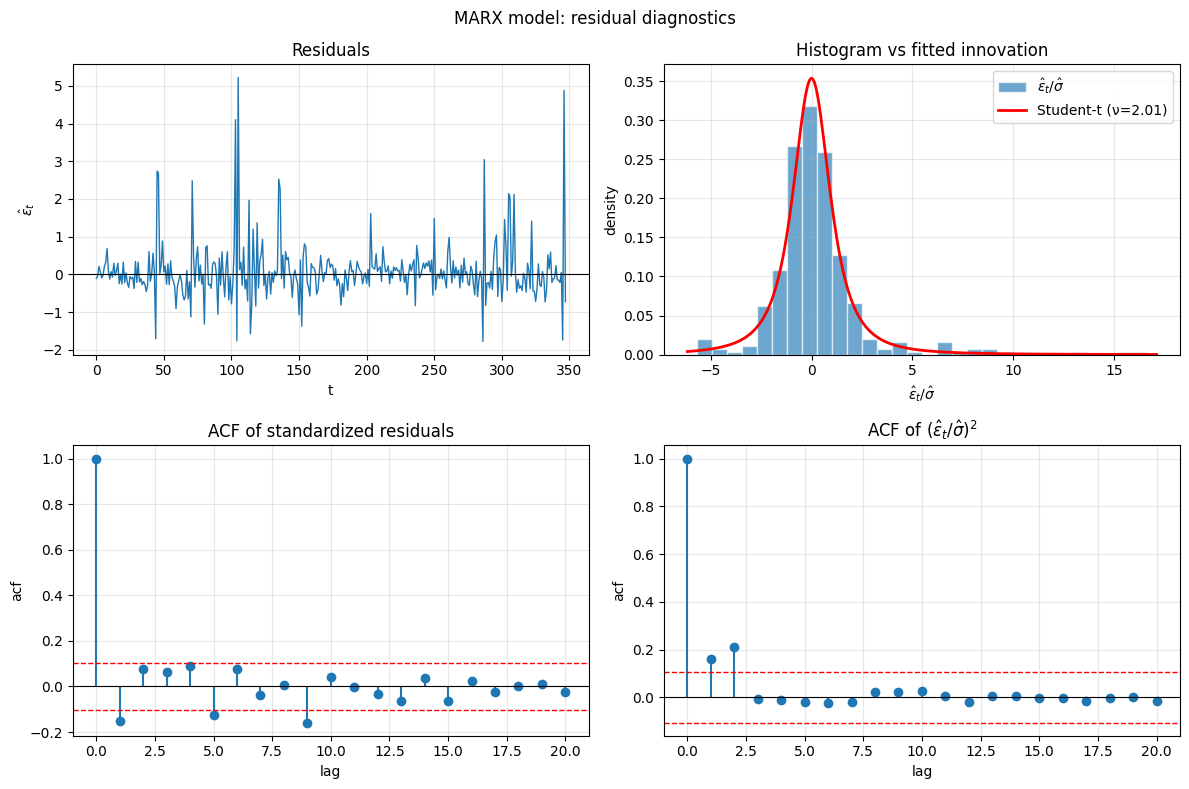

In [28]:
param_names = [ "phi", "psi", "beta_wti", "beta_usd_ind", "beta_indpro", "beta_ngas_storage", "beta_ngas_prod", "beta_fedfunds", "beta_vix", "beta_brent", "beta_epu", "beta_gpr", "beta_ngas_exports", "beta_hdd", "beta_cdd", "beta_sp500", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

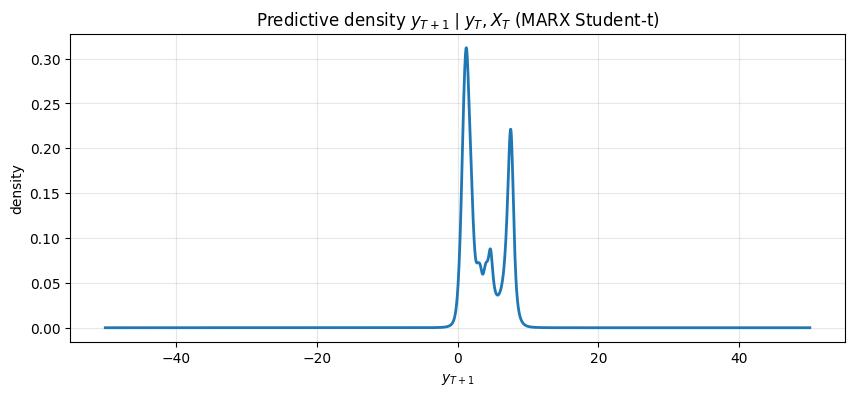

In [29]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

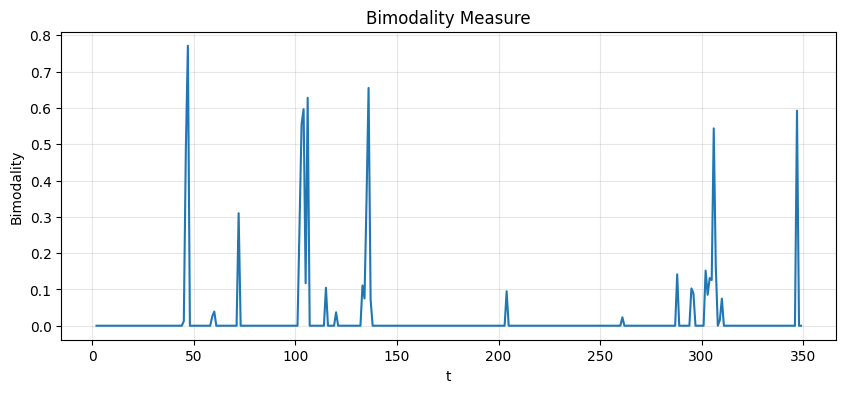

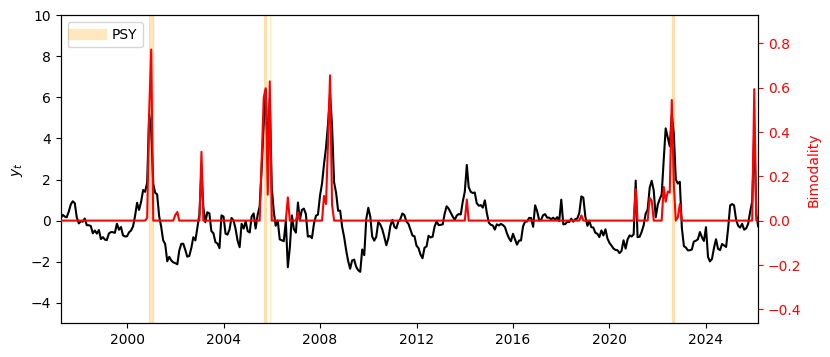

In [30]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)
